<a href="https://colab.research.google.com/github/jeedderh01/case-exercises-for-module-3/blob/main/case_exercise3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Case Exercise 3: Metocean-Fatigue Correlation Model


## 1. Build the JONSWAP-based spectral fatigue pipeline

In [2]:
import numpy as np
import pandas as pd
from scipy.special import gamma

# Load enriched dataset from previous exercises using the correct path
df = pd.read_csv("/content/sample_data/jubilee_trp3_metocean_1year.csv")
df["Timestamp"] = pd.to_datetime(df["Timestamp"])
df = df.sort_values("Timestamp").reset_index(drop=True)

# S-N Curve Parameters for welded steel in seawater (DNV-RP-C203)
m_sn = 3.0  # S-N slope parameter
log_a_sn = 11.764  # Intercept log(A)
A_sn = 10**log_a_sn
K_sn = A_sn

# Transfer function coefficient mapping significant wave height to hot-spot stress range (MPa)
stress_transfer_coeff = 12.5


def compute_spectral_fatigue(hs, tp, duration_seconds=3600):
    """Computes hourly fatigue damage using narrow-band approximation

    and JONSWAP zero-crossing frequency.
    """
    if pd.isna(hs) or pd.isna(tp) or tp <= 0 or hs <= 0:
        return 0.0

    # Zero-crossing period approximation from peak period for JONSWAP (~0.73 * Tp)
    tz = 0.73 * tp
    v0 = 1.0 / tz  # Zero-upcrossing frequency (Hz)
    num_cycles = v0 * duration_seconds

    # Equivalent stress range amplitude scale (Rayleigh distribution expected peak)
    s_rms = stress_transfer_coeff * (hs / (2 * np.sqrt(2)))

    # Expectation of stress range raised to power m using Gamma function
    expected_stress_moment = ((2.0 * s_rms ** 2) ** (m_sn / 2.0)) * gamma(
        1.0 + m_sn / 2.0
    )

    # Miner's Rule Damage Increment: D = (n / K) * E[S^m]
    damage = (num_cycles / K_sn) * expected_stress_moment
    return damage


print("JONSWAP Spectral Fatigue Pipeline initialized successfully.")

JONSWAP Spectral Fatigue Pipeline initialized successfully.


## 2. Compute hourly fatigue damage for the full year of Jubilee TRP3 data.

In [4]:
# Apply pipeline across hourly records using the correct column names
df["hourly_damage"] = df.apply(
    lambda row: compute_spectral_fatigue(
        row["Significant_Wave_Height_m"], row["Peak_Wave_Period_s"]
    ),
    axis=1,
)
df["cumulative_damage"] = df["hourly_damage"].cumsum()

print(f"Total Annual Fatigue Damage: {df['hourly_damage'].sum():.6e}")
print(f"Hourly Damage Dataset Shape: {df.shape}")

Total Annual Fatigue Damage: 1.572872e-02
Hourly Damage Dataset Shape: (8760, 7)


## 3. Build polynomial regression models (degree 1, 2, 3) predicting fatigue from metocean features. Report R² and MAE for each

In [8]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.preprocessing import PolynomialFeatures

# Select correct metocean columns from the dataset
features = [
    "Significant_Wave_Height_m",
    "Peak_Wave_Period_s",
    "Surface_Current_Speed_ms",
    "Wind_Speed_ms",
]
X = df[features].fillna(0)
y = df["hourly_damage"]

poly_results = []

for degree in [1, 2, 3]:
    poly = PolynomialFeatures(degree=degree, include_bias=False)
    X_poly = poly.fit_transform(X)

    model = LinearRegression()
    model.fit(X_poly, y)
    y_pred = model.predict(X_poly)

    r2 = r2_score(y, y_pred)
    mae = mean_absolute_error(y, y_pred)

    poly_results.append(
        {
            "Degree": degree,
            "R2": r2,
            "MAE": mae,
            "Model": model,
            "PolyTransformer": poly,
        }
    )

print("\n=== POLYNOMIAL REGRESSION PERFORMANCE (Full Training) ===")
for res in poly_results:
    print(
        f"Degree {res['Degree']} -> R²: {res['R2']:.4f} | MAE: {res['MAE']:.4e}"
    )


=== POLYNOMIAL REGRESSION PERFORMANCE (Full Training) ===
Degree 1 -> R²: 0.9242 | MAE: 2.9139e-07
Degree 2 -> R²: 0.9996 | MAE: 2.0057e-08
Degree 3 -> R²: 1.0000 | MAE: 2.1037e-09


## 4. Validate using 5-fold cross-validation. Perform residual analysis and identify any systematic model weaknesses.
## 5. Create a dashboard showing: monthly damage accumulation, Hs vs. damage scatter, predicted vs. actual damage, and cumulative damage trajectory


=== 5-FOLD CROSS-VALIDATION SUMMARY ===
 Degree  CV_R2_Mean    CV_R2_Std  CV_MAE_Mean
      1    0.924186 4.292523e-03 2.915592e-07
      2    0.999574 6.859678e-05 2.010856e-08
      3    0.999995 9.067468e-07 2.124452e-09


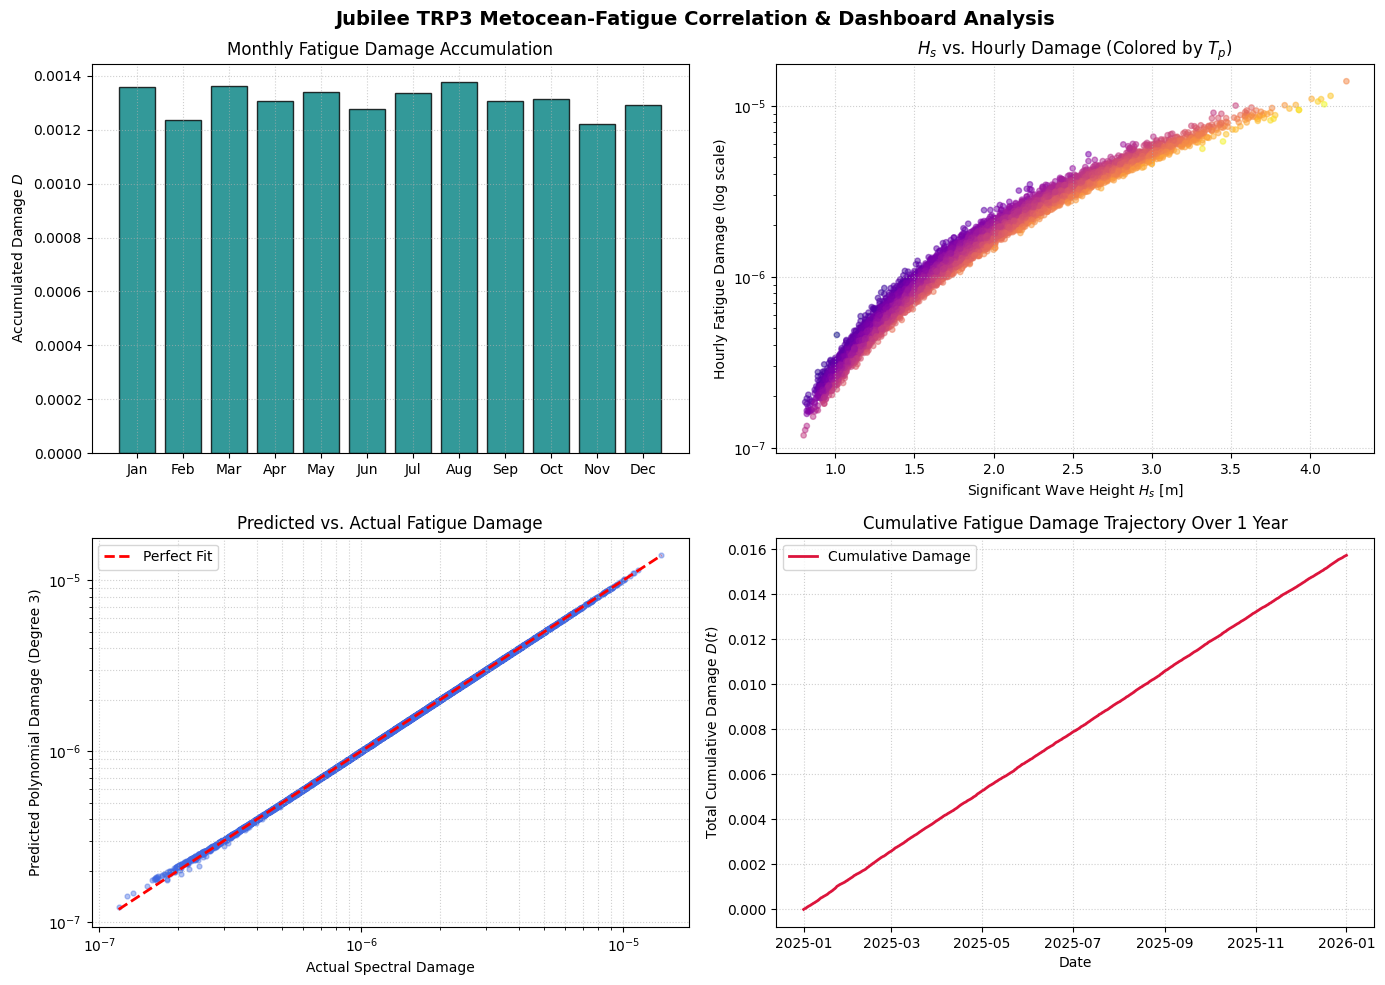

In [10]:
import matplotlib.pyplot as plt
from sklearn.model_selection import KFold

# 1. 5-Fold Cross-Validation
kf = KFold(n_splits=5, shuffle=True, random_state=42)
cv_summary = []

for res in poly_results:
    deg = res["Degree"]
    poly = res["PolyTransformer"]
    X_poly = poly.transform(X)

    fold_r2 = []
    fold_mae = []

    for train_idx, test_idx in kf.split(X_poly):
        X_train, X_test = X_poly[train_idx], X_poly[test_idx]
        y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

        cv_model = LinearRegression()
        cv_model.fit(X_train, y_train)
        y_test_pred = cv_model.predict(X_test)

        fold_r2.append(r2_score(y_test, y_test_pred))
        fold_mae.append(mean_absolute_error(y_test, y_test_pred))

    cv_summary.append(
        {
            "Degree": deg,
            "CV_R2_Mean": np.mean(fold_r2),
            "CV_R2_Std": np.std(fold_r2),
            "CV_MAE_Mean": np.mean(fold_mae),
        }
    )

print("\n=== 5-FOLD CROSS-VALIDATION SUMMARY ===")
cv_df = pd.DataFrame(cv_summary)
print(cv_df.to_string(index=False))

# Select best model (Degree 3) for residual analysis & predictions
best_poly_idx = 2
best_model = poly_results[best_poly_idx]["Model"]
best_X_poly = poly_results[best_poly_idx]["PolyTransformer"].transform(X)
df["predicted_damage"] = best_model.predict(best_X_poly)
df["residuals"] = df["hourly_damage"] - df["predicted_damage"]

# 2. Multi-Panel Damage Dashboard Creation
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# A. Monthly Damage Accumulation - Fixed column name to capitalized 'Timestamp'
monthly_damage = df.set_index("Timestamp")["hourly_damage"].resample("ME").sum()
axes[0, 0].bar(
    range(len(monthly_damage)),
    monthly_damage.values,
    color="teal",
    alpha=0.8,
    edgecolor="k",
)
axes[0, 0].set_xticks(range(len(monthly_damage)))
axes[0, 0].set_xticklabels(
    [d.strftime("%b") for d in monthly_damage.index], rotation=0
)
axes[0, 0].set_title("Monthly Fatigue Damage Accumulation")
axes[0, 0].set_ylabel("Accumulated Damage $D$")
axes[0, 0].grid(True, linestyle=":", alpha=0.6)

# B. Hs vs. Hourly Fatigue Damage Scatter - Fixed column names to match dataset schema
axes[0, 1].scatter(
    df["Significant_Wave_Height_m"],
    df["hourly_damage"],
    c=df["Peak_Wave_Period_s"],
    cmap="plasma",
    alpha=0.5,
    s=15,
)
axes[0, 1].set_yscale("log")
axes[0, 1].set_xlabel("Significant Wave Height $H_s$ [m]")
axes[0, 1].set_ylabel("Hourly Fatigue Damage (log scale)")
axes[0, 1].set_title("$H_s$ vs. Hourly Damage (Colored by $T_p$)")
axes[0, 1].grid(True, linestyle=":", alpha=0.6)

# C. Predicted vs. Actual Damage (Degree 3 Model)
axes[1, 0].scatter(
    df["hourly_damage"],
    df["predicted_damage"],
    color="royalblue",
    alpha=0.4,
    s=12,
)
lims = [
    min(df["hourly_damage"].min(), df["predicted_damage"].min()),
    max(df["hourly_damage"].max(), df["predicted_damage"].max()),
]
axes[1, 0].plot(lims, lims, "r--", lw=2, label="Perfect Fit")
axes[1, 0].set_yscale("log")
axes[1, 0].set_xscale("log")
axes[1, 0].set_xlabel("Actual Spectral Damage")
axes[1, 0].set_ylabel("Predicted Polynomial Damage (Degree 3)")
axes[1, 0].set_title("Predicted vs. Actual Fatigue Damage")
axes[1, 0].legend()
axes[1, 0].grid(True, which="both", linestyle=":", alpha=0.6)

# D. Cumulative Damage Trajectory - Fixed column name to capitalized 'Timestamp'
axes[1, 1].plot(
    df["Timestamp"],
    df["cumulative_damage"],
    color="crimson",
    lw=2,
    label="Cumulative Damage",
)
axes[1, 1].set_xlabel("Date")
axes[1, 1].set_ylabel("Total Cumulative Damage $D(t)$")
axes[1, 1].set_title("Cumulative Fatigue Damage Trajectory Over 1 Year")
axes[1, 1].grid(True, linestyle=":", alpha=0.6)
axes[1, 1].legend()

plt.suptitle(
    "Jubilee TRP3 Metocean-Fatigue Correlation & Dashboard Analysis",
    fontsize=14,
    weight="bold",
)
plt.tight_layout()
plt.show()